# 3B. Training Regressor Models (Exogenous)

This notebook trains and evaluates five regressors on the **exogenous** feature configuration exported by notebook 2 (pipeline 8B): Linear Regression, Decision Tree, Random Forest, MLP and XGBoost. Each model has its own block with four steps: cross-validation, training, evaluation and metrics. The last section compares all models and saves the results for notebook 4.

In [1]:
import pickle
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor

PROJECT_ROOT = next(
    (
        path
        for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "data" / "features").is_dir()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate the thesis project root.")

# Select the system, target and feature configuration.
SYSTEM_ID = 4
TARGET = "dc_power__314"
CONFIG = "exogenous"

METRICS_DIR = PROJECT_ROOT / "artifacts" / "metrics"
EXPERIMENTS_DIR = PROJECT_ROOT / "artifacts" / "experiments"
MODELS_DIR = PROJECT_ROOT / "artifacts" / "models"
EXPERIMENTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)
print(f"Project root: {PROJECT_ROOT}")
print(f"Configuration: {CONFIG}")

Project root: /home/raul/Desktop/solar-data-all/thesis
Configuration: exogenous


## Setup: load the train/test data

Read the `exogenous` row of the configuration summary written by notebook 2, then load its four CSVs with `datetime` as the index. The features are already MinMax-scaled; the target is in watts. If the exogenous data does not exist yet, this cell stops with a message naming the notebook 2 pipeline to run (8B).

In [2]:
CONFIG_SUMMARY_PATH = METRICS_DIR / f"system_{SYSTEM_ID}_feature_configs.csv"
config_summary = pd.read_csv(CONFIG_SUMMARY_PATH, index_col="config")
if CONFIG not in config_summary.index:
    raise FileNotFoundError(
        f"No '{CONFIG}' data in {CONFIG_SUMMARY_PATH.name}; "
        f"run pipeline 8B in notebook 2 first."
    )

group_name = config_summary.loc[CONFIG, "group_name"]
feature_directory = PROJECT_ROOT / "data" / "features" / group_name


def load_partition(part):
    """Load one exported partition with its datetime index."""
    return pd.read_csv(feature_directory / f"{part}_{group_name}.csv",
                       index_col="datetime", parse_dates=True)


X_train, X_test = load_partition("X_train"), load_partition("X_test")
y_train, y_test = load_partition("y_train")[TARGET], load_partition("y_test")[TARGET]

assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)
assert not any(part.isna().any().any() for part in (X_train, X_test, y_train.to_frame(), y_test.to_frame()))
assert X_train.index.max() < X_test.index.min()

FEATURES = list(X_train.columns)
print(f"Features: {FEATURES}")
display(pd.DataFrame(
    {name: {"rows": len(part), "start": part.index.min(), "end": part.index.max()}
     for name, part in {"train": X_train, "test": X_test}.items()}
).T)

Features: ['ambient_temp__320', 'hour_sin', 'hour_cos', 'doy_sin', 'doy_cos']


,rows,start,end
train,1059458,2007-08-26 10:30:00,2016-01-21 08:46:00
test,264865,2016-01-21 08:47:00,2023-01-31 16:17:00


## Setup: shared evaluation

Every model block below uses the same evaluation:

- **Cross-validation:** `TimeSeriesSplit` with `N_SPLITS` expanding folds. Each fold trains on earlier data and validates on the block that follows, so no future data leaks into training. CV runs on every `CV_SUBSAMPLE_STEP`-th training row (time order kept) to keep Random Forest and MLP affordable. It is repeated for every seed in `SEEDS`, so the spread covers both time periods and model randomness.
- **Final model:** fitted on the full training set with the first seed, then scored on the full test set.
- **Metrics:** MAE, RMSE and R², all in watts.

Results are kept in dictionaries keyed by model name, so re-running a block replaces its results instead of duplicating them.

In [3]:
# Cross-validation settings shared by every model.
SEEDS = [0, 1, 2]
N_SPLITS = 5
CV_SUBSAMPLE_STEP = 10

X_cv = X_train.iloc[::CV_SUBSAMPLE_STEP]
y_cv = y_train.iloc[::CV_SUBSAMPLE_STEP]
cv_splitter = TimeSeriesSplit(n_splits=N_SPLITS)

cv_results, test_results, test_predictions = {}, {}, {}


def regression_metrics(y_true, y_pred):
    """MAE, RMSE and R² in the target's units (W)."""
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": r2_score(y_true, y_pred),
    }


def run_cv(make_model, seeds):
    """Time-series CV on the subsample: one row per seed and fold."""
    rows = []
    for seed in seeds:
        for fold, (fit_rows, val_rows) in enumerate(cv_splitter.split(X_cv), start=1):
            model = make_model(seed)
            start = time.perf_counter()
            model.fit(X_cv.iloc[fit_rows], y_cv.iloc[fit_rows])
            fit_seconds = time.perf_counter() - start
            scores = regression_metrics(y_cv.iloc[val_rows], model.predict(X_cv.iloc[val_rows]))
            rows.append({"seed": seed, "fold": fold, "fit_rows": len(fit_rows),
                         "val_rows": len(val_rows), **scores, "fit_seconds": fit_seconds})
    return pd.DataFrame(rows)


def cv_summary(cv_table):
    """Mean and standard deviation of the CV metrics over all seeds and folds."""
    return cv_table[["MAE", "RMSE", "R2"]].agg(["mean", "std"])


def fit_and_time(model, X, y):
    """Fit a model and return the fit time in seconds."""
    start = time.perf_counter()
    model.fit(X, y)
    return time.perf_counter() - start


def predict_and_time(model, X):
    """Predict and return the predictions with the prediction time in seconds."""
    start = time.perf_counter()
    predictions = model.predict(X)
    return predictions, time.perf_counter() - start


def summarize_model(cv_table, train_pred, test_pred, fit_seconds, predict_seconds, model_path):
    """One comparison row: CV mean/std, train and test metrics, timing and model size."""
    stats = cv_summary(cv_table)
    row = {f"cv_{metric}_{stat}": stats.loc[stat, metric]
           for metric in ("MAE", "RMSE", "R2") for stat in ("mean", "std")}
    row.update({f"train_{k}": v for k, v in regression_metrics(y_train, train_pred).items()})
    row.update({f"test_{k}": v for k, v in regression_metrics(y_test, test_pred).items()})
    row.update({"cv_runs": len(cv_table), "fit_seconds": fit_seconds,
                "predict_seconds": predict_seconds,
                "model_size_kb": model_path.stat().st_size / 1024})
    return row


print(f"CV subsample: {len(X_cv):,} of {len(X_train):,} training rows "
      f"({N_SPLITS} folds x {len(SEEDS)} seeds)")

CV subsample: 105,946 of 1,059,458 training rows (5 folds x 3 seeds)


## 3B.1 Linear Regression

The baseline: an ordinary least-squares fit of the target on the features. It has no hyperparameters and no randomness, so cross-validation runs with a single seed; its spread comes from the folds only.

### 3B.1.1 Cross-validation (Linear Regression)

Define the model and run time-series cross-validation on the subsample. The first table has one row per seed and fold; the second gives the mean and standard deviation over all of them.

In [4]:
def make_linear_regression(seed):
    """LinearRegression has no randomness; the seed is ignored."""
    return LinearRegression()


cv_results["Linear Regression"] = run_cv(make_linear_regression, seeds=SEEDS[:1])
display(cv_results["Linear Regression"].round(3))
display(cv_summary(cv_results["Linear Regression"]).round(3))

,seed,fold,fit_rows,val_rows,MAE,RMSE,R2,fit_seconds
0,0,1,17661,17657,178.536,222.198,0.477,0.009
1,0,2,35318,17657,181.496,231.060,0.419,0.004
2,0,3,52975,17657,181.433,223.967,0.464,0.005
3,0,4,70632,17657,186.200,233.603,0.388,0.006
4,0,5,88289,17657,175.361,217.838,0.462,0.008


,MAE,RMSE,R2
mean,180.605,225.733,0.442
std,4.018,6.486,0.037


### 3B.1.2 Training (Linear Regression)

Fit the final model on the full training set with the first seed and record the fit time.

In [5]:
lr_model = make_linear_regression(SEEDS[0])
lr_fit_seconds = fit_and_time(lr_model, X_train, y_train)
print(f"Linear Regression: fitted on {len(X_train):,} rows in {lr_fit_seconds:.1f} s")

Linear Regression: fitted on 1,059,458 rows in 0.1 s


### 3B.1.3 Evaluation (Linear Regression)

Predict on the training and test sets. A test score far below the training score points to overfitting; the test predictions are kept for the comparison and for the plots in notebook 4.

In [6]:
lr_train_pred, _ = predict_and_time(lr_model, X_train)
lr_test_pred, lr_predict_seconds = predict_and_time(lr_model, X_test)
test_predictions["Linear Regression"] = lr_test_pred

display(pd.DataFrame({"train": regression_metrics(y_train, lr_train_pred),
                      "test": regression_metrics(y_test, lr_test_pred)}).T.round(3))
print(f"Test prediction time: {lr_predict_seconds:.2f} s for {len(X_test):,} rows")

,MAE,RMSE,R2
train,184.027,225.28,0.453
test,180.959,223.05,0.450


Test prediction time: 0.01 s for 264,865 rows


### 3B.1.4 Metrics (Linear Regression)

Save the fitted model to `artifacts/models/` and collect its comparison row: CV mean and standard deviation, train and test metrics, fit and prediction time, and the size of the saved model.

In [7]:
lr_model_path = MODELS_DIR / f"system_{SYSTEM_ID}_{CONFIG}_linear_regression.pkl"
with lr_model_path.open("wb") as model_file:
    pickle.dump(lr_model, model_file)

test_results["Linear Regression"] = summarize_model(cv_results["Linear Regression"], lr_train_pred, lr_test_pred,
                                         lr_fit_seconds, lr_predict_seconds, lr_model_path)
display(pd.Series(test_results["Linear Regression"], name="Linear Regression").to_frame().round(3))
print(f"Model saved to: {lr_model_path}")

,Linear Regression
cv_MAE_mean,180.605
cv_MAE_std,4.018
cv_RMSE_mean,225.733
cv_RMSE_std,6.486
cv_R2_mean,0.442
cv_R2_std,0.037
train_MAE,184.027
train_RMSE,225.280
train_R2,0.453
test_MAE,180.959


Model saved to: /home/raul/Desktop/solar-data-all/thesis/artifacts/models/system_4_exogenous_linear_regression.pkl


## 3B.2 Decision Tree

A single regression tree. `DT_MAX_DEPTH` and `DT_MIN_SAMPLES_LEAF` limit its size; an unlimited tree on more than a million rows would memorise noise and grow very large.

### 3B.2.1 Cross-validation (Decision Tree)

Define the model and run time-series cross-validation on the subsample. The first table has one row per seed and fold; the second gives the mean and standard deviation over all of them.

In [8]:
# Decision Tree hyperparameters (fixed, not tuned).
DT_MAX_DEPTH = 12
DT_MIN_SAMPLES_LEAF = 50


def make_decision_tree(seed):
    return DecisionTreeRegressor(max_depth=DT_MAX_DEPTH, min_samples_leaf=DT_MIN_SAMPLES_LEAF,
                                 random_state=seed)


cv_results["Decision Tree"] = run_cv(make_decision_tree, seeds=SEEDS)
display(cv_results["Decision Tree"].round(3))
display(cv_summary(cv_results["Decision Tree"]).round(3))

,seed,fold,fit_rows,val_rows,MAE,RMSE,R2,fit_seconds
0,0,1,17661,17657,164.898,230.424,0.437,0.043
1,0,2,35318,17657,175.663,238.430,0.381,0.079
2,0,3,52975,17657,174.321,233.761,0.416,0.123
3,0,4,70632,17657,175.705,238.698,0.361,0.169
4,0,5,88289,17657,163.727,221.528,0.443,0.215
5,1,1,17661,17657,164.908,230.434,0.437,0.037
6,1,2,35318,17657,175.663,238.430,0.381,0.080
7,1,3,52975,17657,174.327,233.773,0.416,0.124
8,1,4,70632,17657,175.801,238.771,0.360,0.170
9,1,5,88289,17657,163.757,221.573,0.443,0.215


,MAE,RMSE,R2
mean,170.942,232.669,0.407
std,5.502,6.516,0.033


### 3B.2.2 Training (Decision Tree)

Fit the final model on the full training set with the first seed and record the fit time.

In [9]:
dt_model = make_decision_tree(SEEDS[0])
dt_fit_seconds = fit_and_time(dt_model, X_train, y_train)
print(f"Decision Tree: fitted on {len(X_train):,} rows in {dt_fit_seconds:.1f} s")

Decision Tree: fitted on 1,059,458 rows in 2.8 s


### 3B.2.3 Evaluation (Decision Tree)

Predict on the training and test sets. A test score far below the training score points to overfitting; the test predictions are kept for the comparison and for the plots in notebook 4.

In [10]:
dt_train_pred, _ = predict_and_time(dt_model, X_train)
dt_test_pred, dt_predict_seconds = predict_and_time(dt_model, X_test)
test_predictions["Decision Tree"] = dt_test_pred

display(pd.DataFrame({"train": regression_metrics(y_train, dt_train_pred),
                      "test": regression_metrics(y_test, dt_test_pred)}).T.round(3))
print(f"Test prediction time: {dt_predict_seconds:.2f} s for {len(X_test):,} rows")

,MAE,RMSE,R2
train,147.670,197.170,0.581
test,171.638,232.003,0.405


Test prediction time: 0.01 s for 264,865 rows


### 3B.2.4 Metrics (Decision Tree)

Save the fitted model to `artifacts/models/` and collect its comparison row: CV mean and standard deviation, train and test metrics, fit and prediction time, and the size of the saved model.

In [11]:
dt_model_path = MODELS_DIR / f"system_{SYSTEM_ID}_{CONFIG}_decision_tree.pkl"
with dt_model_path.open("wb") as model_file:
    pickle.dump(dt_model, model_file)

test_results["Decision Tree"] = summarize_model(cv_results["Decision Tree"], dt_train_pred, dt_test_pred,
                                         dt_fit_seconds, dt_predict_seconds, dt_model_path)
display(pd.Series(test_results["Decision Tree"], name="Decision Tree").to_frame().round(3))
print(f"Model saved to: {dt_model_path}")

,Decision Tree
cv_MAE_mean,170.942
cv_MAE_std,5.502
cv_RMSE_mean,232.669
cv_RMSE_std,6.516
cv_R2_mean,0.407
cv_R2_std,0.033
train_MAE,147.670
train_RMSE,197.170
train_R2,0.581
test_MAE,171.638


Model saved to: /home/raul/Desktop/solar-data-all/thesis/artifacts/models/system_4_exogenous_decision_tree.pkl


## 3B.3 Random Forest

An average of `RF_N_ESTIMATORS` trees, each grown on a bootstrap sample of the rows. The same depth and leaf limits as the single tree keep the saved model to a few MB.

### 3B.3.1 Cross-validation (Random Forest)

Define the model and run time-series cross-validation on the subsample. The first table has one row per seed and fold; the second gives the mean and standard deviation over all of them.

In [12]:
# Random Forest hyperparameters (fixed, not tuned).
RF_N_ESTIMATORS = 100
RF_MAX_DEPTH = 12
RF_MIN_SAMPLES_LEAF = 50


def make_random_forest(seed):
    return RandomForestRegressor(n_estimators=RF_N_ESTIMATORS, max_depth=RF_MAX_DEPTH,
                                 min_samples_leaf=RF_MIN_SAMPLES_LEAF, n_jobs=-1,
                                 random_state=seed)


cv_results["Random Forest"] = run_cv(make_random_forest, seeds=SEEDS)
display(cv_results["Random Forest"].round(3))
display(cv_summary(cv_results["Random Forest"]).round(3))

,seed,fold,fit_rows,val_rows,MAE,RMSE,R2,fit_seconds
0,0,1,17661,17657,161.245,215.188,0.509,0.304
1,0,2,35318,17657,173.309,229.463,0.427,0.658
2,0,3,52975,17657,170.528,221.147,0.477,1.017
3,0,4,70632,17657,173.204,230.404,0.404,1.415
4,0,5,88289,17657,162.756,213.728,0.482,1.791
5,1,1,17661,17657,161.181,215.040,0.510,0.300
6,1,2,35318,17657,173.470,229.960,0.424,0.656
7,1,3,52975,17657,170.459,221.206,0.477,1.023
8,1,4,70632,17657,173.212,230.150,0.406,1.393
9,1,5,88289,17657,162.772,213.858,0.481,1.781


,MAE,RMSE,R2
mean,168.205,222.016,0.46
std,5.394,7.252,0.04


### 3B.3.2 Training (Random Forest)

Fit the final model on the full training set with the first seed and record the fit time.

In [13]:
rf_model = make_random_forest(SEEDS[0])
rf_fit_seconds = fit_and_time(rf_model, X_train, y_train)
print(f"Random Forest: fitted on {len(X_train):,} rows in {rf_fit_seconds:.1f} s")

Random Forest: fitted on 1,059,458 rows in 24.2 s


### 3B.3.3 Evaluation (Random Forest)

Predict on the training and test sets. A test score far below the training score points to overfitting; the test predictions are kept for the comparison and for the plots in notebook 4.

In [14]:
rf_train_pred, _ = predict_and_time(rf_model, X_train)
rf_test_pred, rf_predict_seconds = predict_and_time(rf_model, X_test)
test_predictions["Random Forest"] = rf_test_pred

display(pd.DataFrame({"train": regression_metrics(y_train, rf_train_pred),
                      "test": regression_metrics(y_test, rf_test_pred)}).T.round(3))
print(f"Test prediction time: {rf_predict_seconds:.2f} s for {len(X_test):,} rows")

,MAE,RMSE,R2
train,146.792,191.990,0.603
test,167.508,222.785,0.451


Test prediction time: 0.11 s for 264,865 rows


### 3B.3.4 Metrics (Random Forest)

Save the fitted model to `artifacts/models/` and collect its comparison row: CV mean and standard deviation, train and test metrics, fit and prediction time, and the size of the saved model.

In [15]:
rf_model_path = MODELS_DIR / f"system_{SYSTEM_ID}_{CONFIG}_random_forest.pkl"
with rf_model_path.open("wb") as model_file:
    pickle.dump(rf_model, model_file)

test_results["Random Forest"] = summarize_model(cv_results["Random Forest"], rf_train_pred, rf_test_pred,
                                         rf_fit_seconds, rf_predict_seconds, rf_model_path)
display(pd.Series(test_results["Random Forest"], name="Random Forest").to_frame().round(3))
print(f"Model saved to: {rf_model_path}")

,Random Forest
cv_MAE_mean,168.205
cv_MAE_std,5.394
cv_RMSE_mean,222.016
cv_RMSE_std,7.252
cv_R2_mean,0.460
cv_R2_std,0.040
train_MAE,146.792
train_RMSE,191.990
train_R2,0.603
test_MAE,167.508


Model saved to: /home/raul/Desktop/solar-data-all/thesis/artifacts/models/system_4_exogenous_random_forest.pkl


## 3B.4 MLP

A feed-forward neural network with two hidden layers, trained with Adam and early stopping on an internal 10% validation split. The target is in watts (up to about 1,300 W), which is a poor scale for training a network, so `TransformedTargetRegressor` standardises `y` inside the model; predictions and metrics stay in watts.

### 3B.4.1 Cross-validation (MLP)

Define the model and run time-series cross-validation on the subsample. The first table has one row per seed and fold; the second gives the mean and standard deviation over all of them.

In [16]:
# MLP hyperparameters (fixed, not tuned).
MLP_HIDDEN_LAYERS = (64, 32)
MLP_MAX_ITER = 200
MLP_BATCH_SIZE = 1024


def make_mlp(seed):
    network = MLPRegressor(hidden_layer_sizes=MLP_HIDDEN_LAYERS, max_iter=MLP_MAX_ITER,
                           batch_size=MLP_BATCH_SIZE, early_stopping=True, random_state=seed)
    return TransformedTargetRegressor(regressor=network, transformer=StandardScaler())


cv_results["MLP"] = run_cv(make_mlp, seeds=SEEDS)
display(cv_results["MLP"].round(3))
display(cv_summary(cv_results["MLP"]).round(3))

/home/raul/Desktop/solar-data-all/myenv/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


,seed,fold,fit_rows,val_rows,MAE,RMSE,R2,fit_seconds
0,0,1,17661,17657,159.465,211.691,0.525,1.735
1,0,2,35318,17657,170.613,229.020,0.429,5.046
2,0,3,52975,17657,164.364,212.235,0.518,7.770
3,0,4,70632,17657,170.008,227.551,0.419,7.472
4,0,5,88289,17657,160.960,210.217,0.499,6.038
5,1,1,17661,17657,158.770,211.269,0.527,1.582
6,1,2,35318,17657,171.273,232.125,0.413,7.380
7,1,3,52975,17657,163.707,211.251,0.523,4.447
8,1,4,70632,17657,172.210,226.367,0.425,5.603
9,1,5,88289,17657,162.235,210.515,0.497,7.303


,MAE,RMSE,R2
mean,165.615,218.001,0.479
std,5.060,8.745,0.047


### 3B.4.2 Training (MLP)

Fit the final model on the full training set with the first seed and record the fit time.

In [17]:
mlp_model = make_mlp(SEEDS[0])
mlp_fit_seconds = fit_and_time(mlp_model, X_train, y_train)
print(f"MLP: fitted on {len(X_train):,} rows in {mlp_fit_seconds:.1f} s")

MLP: fitted on 1,059,458 rows in 84.0 s


### 3B.4.3 Evaluation (MLP)

Predict on the training and test sets. A test score far below the training score points to overfitting; the test predictions are kept for the comparison and for the plots in notebook 4.

In [18]:
mlp_train_pred, _ = predict_and_time(mlp_model, X_train)
mlp_test_pred, mlp_predict_seconds = predict_and_time(mlp_model, X_test)
test_predictions["MLP"] = mlp_test_pred

display(pd.DataFrame({"train": regression_metrics(y_train, mlp_train_pred),
                      "test": regression_metrics(y_test, mlp_test_pred)}).T.round(3))
print(f"Test prediction time: {mlp_predict_seconds:.2f} s for {len(X_test):,} rows")

,MAE,RMSE,R2
train,161.888,207.873,0.535
test,166.496,217.159,0.478


Test prediction time: 0.09 s for 264,865 rows


### 3B.4.4 Metrics (MLP)

Save the fitted model to `artifacts/models/` and collect its comparison row: CV mean and standard deviation, train and test metrics, fit and prediction time, and the size of the saved model.

In [19]:
mlp_model_path = MODELS_DIR / f"system_{SYSTEM_ID}_{CONFIG}_mlp.pkl"
with mlp_model_path.open("wb") as model_file:
    pickle.dump(mlp_model, model_file)

test_results["MLP"] = summarize_model(cv_results["MLP"], mlp_train_pred, mlp_test_pred,
                                         mlp_fit_seconds, mlp_predict_seconds, mlp_model_path)
display(pd.Series(test_results["MLP"], name="MLP").to_frame().round(3))
print(f"Model saved to: {mlp_model_path}")

,MLP
cv_MAE_mean,165.615
cv_MAE_std,5.060
cv_RMSE_mean,218.001
cv_RMSE_std,8.745
cv_R2_mean,0.479
cv_R2_std,0.047
train_MAE,161.888
train_RMSE,207.873
train_R2,0.535
test_MAE,166.496


Model saved to: /home/raul/Desktop/solar-data-all/thesis/artifacts/models/system_4_exogenous_mlp.pkl


## 3B.5 XGBoost

Gradient-boosted trees: `XGB_N_ESTIMATORS` shallow trees, each fitted to the errors of the ones before it. The hyperparameters are the values in `configs/train_config.yaml`, except `XGB_COLSAMPLE_BYTREE = 1.0`: with only two endogenous features, the configured 0.8 would give each tree a single feature. The same value is used for both configurations so their results are comparable.

### 3B.5.1 Cross-validation (XGBoost)

Define the model and run time-series cross-validation on the subsample. The first table has one row per seed and fold; the second gives the mean and standard deviation over all of them.

In [20]:
# XGBoost hyperparameters (configs/train_config.yaml, colsample_bytree raised to 1.0; not tuned).
XGB_N_ESTIMATORS = 500
XGB_LEARNING_RATE = 0.05
XGB_MAX_DEPTH = 6
XGB_SUBSAMPLE = 0.8
XGB_COLSAMPLE_BYTREE = 1.0


def make_xgboost(seed):
    return XGBRegressor(n_estimators=XGB_N_ESTIMATORS, learning_rate=XGB_LEARNING_RATE,
                        max_depth=XGB_MAX_DEPTH, subsample=XGB_SUBSAMPLE,
                        colsample_bytree=XGB_COLSAMPLE_BYTREE, n_jobs=-1, random_state=seed)


cv_results["XGBoost"] = run_cv(make_xgboost, seeds=SEEDS)
display(cv_results["XGBoost"].round(3))
display(cv_summary(cv_results["XGBoost"]).round(3))

,seed,fold,fit_rows,val_rows,MAE,RMSE,R2,fit_seconds
0,0,1,17661,17657,164.102,225.944,0.459,0.474
1,0,2,35318,17657,174.269,237.684,0.385,0.267
2,0,3,52975,17657,175.429,234.948,0.410,0.363
3,0,4,70632,17657,174.913,236.347,0.373,0.414
4,0,5,88289,17657,164.607,221.172,0.445,0.401
5,1,1,17661,17657,164.479,226.422,0.456,0.215
6,1,2,35318,17657,174.249,237.546,0.385,0.266
7,1,3,52975,17657,175.629,235.144,0.409,0.311
8,1,4,70632,17657,175.109,237.093,0.369,0.351
9,1,5,88289,17657,164.677,220.831,0.447,0.397


,MAE,RMSE,R2
mean,170.693,231.231,0.414
std,5.387,6.816,0.035


### 3B.5.2 Training (XGBoost)

Fit the final model on the full training set with the first seed and record the fit time.

In [21]:
xgb_model = make_xgboost(SEEDS[0])
xgb_fit_seconds = fit_and_time(xgb_model, X_train, y_train)
print(f"XGBoost: fitted on {len(X_train):,} rows in {xgb_fit_seconds:.1f} s")

XGBoost: fitted on 1,059,458 rows in 4.0 s


### 3B.5.3 Evaluation (XGBoost)

Predict on the training and test sets. A test score far below the training score points to overfitting; the test predictions are kept for the comparison and for the plots in notebook 4.

In [22]:
xgb_train_pred, _ = predict_and_time(xgb_model, X_train)
xgb_test_pred, xgb_predict_seconds = predict_and_time(xgb_model, X_test)
test_predictions["XGBoost"] = xgb_test_pred

display(pd.DataFrame({"train": regression_metrics(y_train, xgb_train_pred),
                      "test": regression_metrics(y_test, xgb_test_pred)}).T.round(3))
print(f"Test prediction time: {xgb_predict_seconds:.2f} s for {len(X_test):,} rows")

,MAE,RMSE,R2
train,137.707,180.154,0.650
test,166.968,222.247,0.454


Test prediction time: 0.18 s for 264,865 rows


### 3B.5.4 Metrics (XGBoost)

Save the fitted model to `artifacts/models/` and collect its comparison row: CV mean and standard deviation, train and test metrics, fit and prediction time, and the size of the saved model.

In [23]:
xgb_model_path = MODELS_DIR / f"system_{SYSTEM_ID}_{CONFIG}_xgboost.pkl"
with xgb_model_path.open("wb") as model_file:
    pickle.dump(xgb_model, model_file)

test_results["XGBoost"] = summarize_model(cv_results["XGBoost"], xgb_train_pred, xgb_test_pred,
                                         xgb_fit_seconds, xgb_predict_seconds, xgb_model_path)
display(pd.Series(test_results["XGBoost"], name="XGBoost").to_frame().round(3))
print(f"Model saved to: {xgb_model_path}")

,XGBoost
cv_MAE_mean,170.693
cv_MAE_std,5.387
cv_RMSE_mean,231.231
cv_RMSE_std,6.816
cv_R2_mean,0.414
cv_R2_std,0.035
train_MAE,137.707
train_RMSE,180.154
train_R2,0.650
test_MAE,166.968


Model saved to: /home/raul/Desktop/solar-data-all/thesis/artifacts/models/system_4_exogenous_xgboost.pkl


## 3B.6 Model comparison summary

One row per model with its CV and test metrics, timing and size, saved to `artifacts/metrics/`. The fold-level CV results and the test predictions of every model are saved to `artifacts/experiments/` for notebook 4. The chart compares test RMSE (bars) with the CV RMSE mean ± standard deviation (points); the CV scores come from the training subsample, so they show stability rather than an exact match with the test score.

,cv_RMSE_mean,cv_RMSE_std,test_MAE,test_RMSE,test_R2,fit_seconds,predict_seconds,model_size_kb
model,,,,,,,,
Linear Regression,225.733,6.486,180.959,223.050,0.450,0.078,0.006,0.683
Decision Tree,232.669,6.516,171.638,232.003,0.405,2.751,0.007,352.957
Random Forest,222.016,7.252,167.508,222.785,0.451,24.198,0.107,29975.080
MLP,218.001,8.745,166.496,217.159,0.478,84.029,0.095,68.560
XGBoost,231.231,6.816,166.968,222.247,0.454,3.978,0.182,2416.165


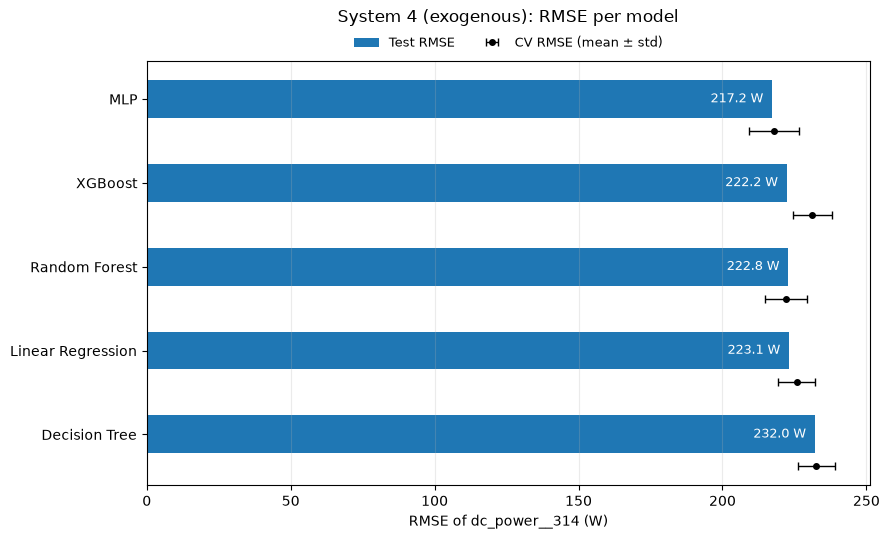

Model metrics saved to: /home/raul/Desktop/solar-data-all/thesis/artifacts/metrics/system_4_exogenous_model_metrics.csv
CV folds saved to: /home/raul/Desktop/solar-data-all/thesis/artifacts/experiments/system_4_exogenous_cv_folds.csv
Test predictions saved to: /home/raul/Desktop/solar-data-all/thesis/artifacts/experiments/system_4_exogenous_test_predictions.csv
RMSE plot saved to: /home/raul/Desktop/solar-data-all/thesis/artifacts/metrics/system_4_exogenous_model_rmse.png


In [24]:
model_metrics = pd.DataFrame(test_results).T.rename_axis("model")
cv_folds = pd.concat(cv_results, names=["model", None]).reset_index(level="model")
predictions = pd.DataFrame({"y_true": y_test, **test_predictions}, index=y_test.index)

MODEL_METRICS_PATH = METRICS_DIR / f"system_{SYSTEM_ID}_{CONFIG}_model_metrics.csv"
CV_FOLDS_PATH = EXPERIMENTS_DIR / f"system_{SYSTEM_ID}_{CONFIG}_cv_folds.csv"
PREDICTIONS_PATH = EXPERIMENTS_DIR / f"system_{SYSTEM_ID}_{CONFIG}_test_predictions.csv"
model_metrics.to_csv(MODEL_METRICS_PATH)
cv_folds.to_csv(CV_FOLDS_PATH, index=False)
predictions.to_csv(PREDICTIONS_PATH)

display(model_metrics[["cv_RMSE_mean", "cv_RMSE_std", "test_MAE", "test_RMSE", "test_R2",
                       "fit_seconds", "predict_seconds", "model_size_kb"]].round(3))

RMSE_PLOT_PATH = METRICS_DIR / f"system_{SYSTEM_ID}_{CONFIG}_model_rmse.png"
order = model_metrics.sort_values("test_RMSE", ascending=False)
positions = np.arange(len(order))
fig, ax = plt.subplots(figsize=(9, 0.8 * len(order) + 1.5))
ax.barh(positions, order["test_RMSE"], height=0.45, color="tab:blue", label="Test RMSE")
# CV points sit just below each bar so they never cover the bar labels.
ax.errorbar(order["cv_RMSE_mean"], positions - 0.38, xerr=order["cv_RMSE_std"], fmt="o",
            color="black", markersize=4, capsize=3, linewidth=1,
            label="CV RMSE (mean ± std)")
for position, rmse in zip(positions, order["test_RMSE"]):
    ax.annotate(f"{rmse:.1f} W", (rmse, position), xytext=(-6, 0), textcoords="offset points",
                ha="right", va="center", fontsize=9, color="white")
ax.set_yticks(positions, order.index)
ax.set_xlabel(f"RMSE of {TARGET} (W)")
ax.set_title(f"System {SYSTEM_ID} ({CONFIG}): RMSE per model", pad=28)
ax.grid(True, axis="x", alpha=0.25)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(RMSE_PLOT_PATH, dpi=160)
plt.show()

print(f"Model metrics saved to: {MODEL_METRICS_PATH}")
print(f"CV folds saved to: {CV_FOLDS_PATH}")
print(f"Test predictions saved to: {PREDICTIONS_PATH}")
print(f"RMSE plot saved to: {RMSE_PLOT_PATH}")